In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv('UsArrests.csv', sep=None, engine='python', index_col=0)
df.head()

,Murder,Assault,UrbanPop,Rape
﻿City,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [3]:
print("Dataset Summary:")
print(df.info())
print("Missing Values:", df.isnull().sum().sum())

Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 2.0+ KB
None
Missing Values: 0


In [4]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_data, columns=df.columns, index=df.index)

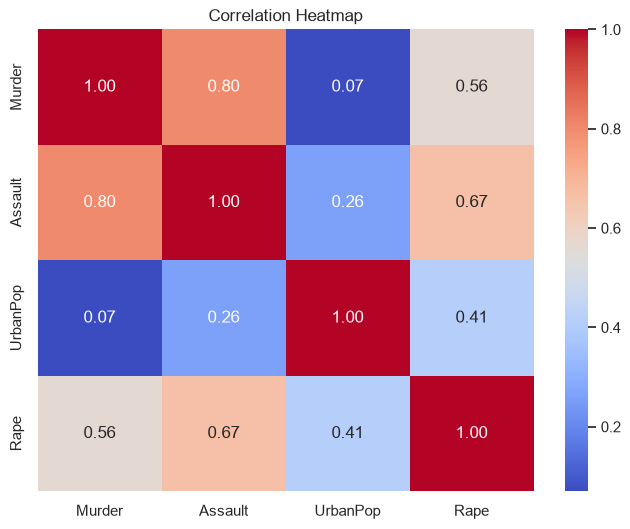

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

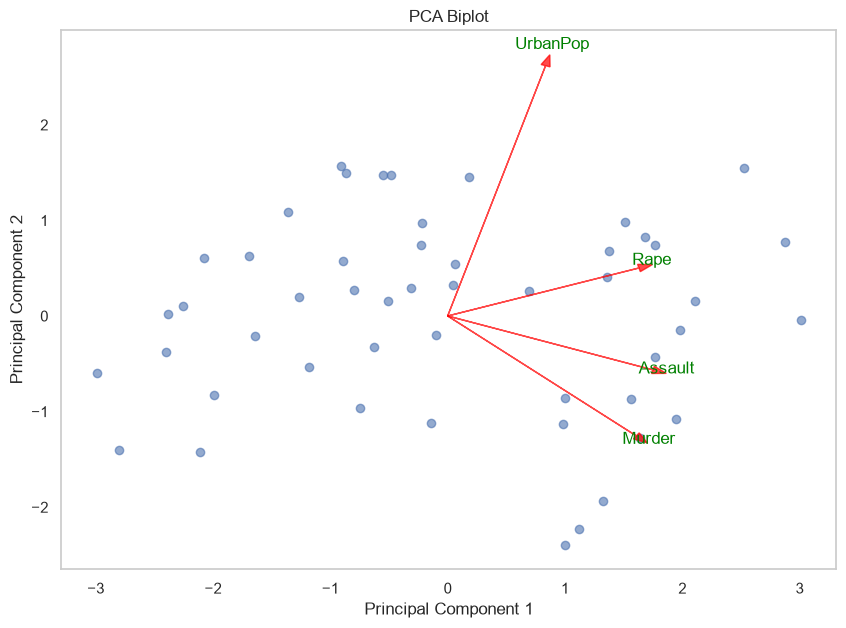

In [6]:
pca = PCA()
pca_data = pca.fit_transform(df_scaled)

def plot_biplot(scores, coefficients, labels):
    plt.figure(figsize=(10, 7))
    plt.scatter(scores[:, 0], scores[:, 1], alpha=0.6)

    for index, label in enumerate(labels):
        plt.arrow(
            0, 0,
            coefficients[index, 0] * 3,
            coefficients[index, 1] * 3,
            color="red",
            alpha=0.7,
            head_width=0.08,
        )
        plt.text(
            coefficients[index, 0] * 3.2,
            coefficients[index, 1] * 3.2,
            label,
            color="green",
            ha="center",
        )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA Biplot")
    plt.grid()
    plt.show()

plot_biplot(
    pca_data[:, :2],
    pca.components_[:2, :].T,
    df.columns,
)

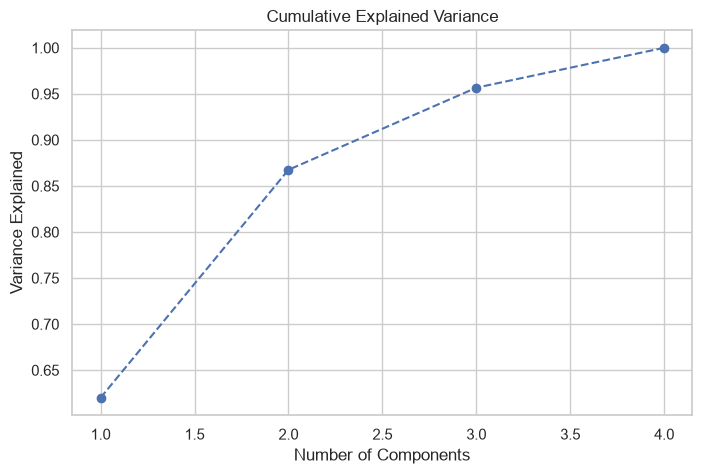

In [7]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 5), cumulative_variance, marker='o', linestyle='--')
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Variance Explained")
plt.show()

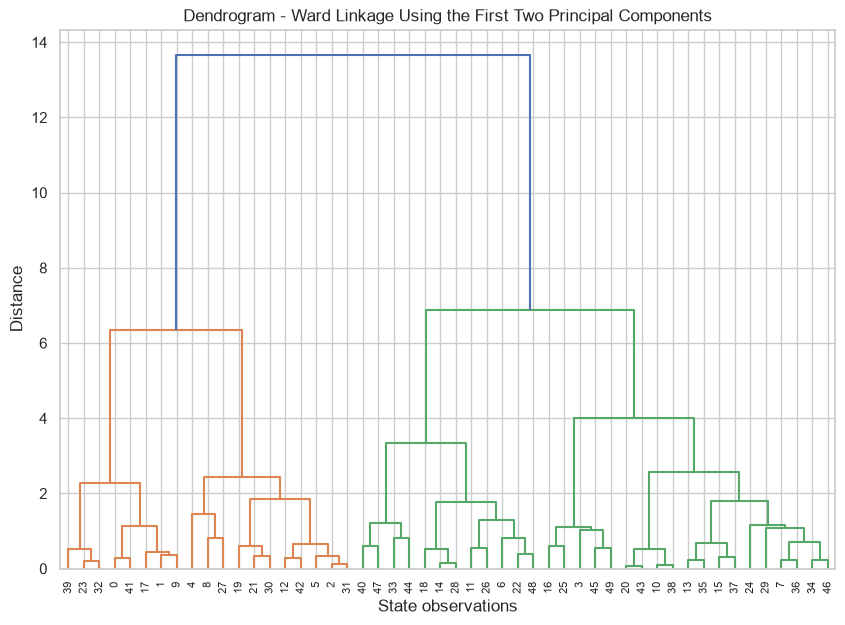

Cluster Analysis Summary (mean original feature values):
         Murder     Assault   UrbanPop       Rape
Cluster                                          
0         4.870  114.433333  63.633333  15.943333
1        12.165  255.250000  68.400000  29.165000


c:\Users\lesed\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [8]:
pca_features = pca_data[:, :2]

plt.figure(figsize=(10, 7))
plt.title("Dendrogram - Ward Linkage Using the First Two Principal Components")
dendrogram(linkage(pca_features, method="ward"))
plt.xlabel("State observations")
plt.ylabel("Distance")
plt.show()

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(pca_features)

print("Cluster Analysis Summary (mean original feature values):")
print(df.groupby("Cluster").mean())

## Data quality and preprocessing

The dataset contains 50 states and four numerical features, with no missing values. The features use different scales, so standardisation is necessary before PCA and clustering. Standardising gives each feature equal opportunity to influence distance calculations and principal components.


Murder and Assault have a strong positive correlation and Assault and Rape also have a clear positive relationship.
This shows that some crime-rate features contain overlapping information.
UrbanPop is less strongly related to the crime-rate variables, so it adds a different aspect of each state's profile.
PCA is appropriate because it can summarise these related features into a smaller number of uncorrelated components.

The arrows for Murder, Assault, and Rape point in broadly similar directions, confirming that they contribute to a shared violent-crime pattern.
States projected in that direction have comparatively higher values for these crime measures.
UrbanPop contributes a distinct direction, helping the second principal component distinguish differences in urbanisation from overall violent-crime levels.

The first two principal components should be retained for the clustering analysis,
together they account for about 87% of the total standardised variance.
This preserves most of the information in the four features while reducing the analysis to a clear two-dimensional representation.


The dendrogram and K-Means model both support a two-cluster solution.
Cluster 1 has higher average Murder, Assault and Rape rates than Cluster 0, so it represents states with comparatively higher violent-crime profiles.
Cluster 0 contains states with lower average violent-crime values.
The states within each cluster are similar because their standardised crime and urban-population measurements place them close together in the feature space.